In [26]:
# Data handling
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt

# Operating system and model saving
import os
import joblib

# Train-test split
from sklearn.model_selection import train_test_split

# Data preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.base import clone

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    ConfusionMatrixDisplay,
    classification_report
)

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
Pandas version: 2.2.2
NumPy version: 1.26.4


In [15]:
# Load the dataset
df = pd.read_csv("bank-full.csv", sep=";")

# Display basic information
print("Dataset Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["y"].value_counts())

print("\nTarget Distribution (%):")
print(df["y"].value_counts(normalize=True) * 100)

Dataset Shape: (45211, 17)

First 5 rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 

In [16]:
# Check duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

# Check unknown values in categorical columns
categorical_cols = df.select_dtypes(include="object").columns

print("\nUnknown values in categorical columns:")
for col in categorical_cols:
    count = (df[col] == "unknown").sum()
    if count > 0:
        print(f"{col}: {count}")

# Check numerical statistics
print("\nNumerical feature summary:")
display(df.describe())

Number of duplicate rows: 0

Unknown values in categorical columns:
job: 288
education: 1857
contact: 13020
poutcome: 36959

Numerical feature summary:


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [17]:
from sklearn.model_selection import train_test_split

# Exclude duration to avoid information leakage
X = df.drop(columns=["y", "duration"])

# Convert target variable into binary format
y = df["y"].map({"no": 0, "yes": 1})

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Training data shape: (36168, 15)
Testing data shape: (9043, 15)

Training target distribution:
y
0    88.301814
1    11.698186
Name: proportion, dtype: float64

Testing target distribution:
y
0    88.300343
1    11.699657
Name: proportion, dtype: float64


In [24]:
# Numerical feature preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical feature preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [30]:
# Make the preprocessing output dense for Gaussian Naive Bayes
preprocessor.set_params(sparse_threshold=0.0)

# Define the five classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "SVM": LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        dual="auto",
        random_state=42
    )
}

# Train all five models
trained_models = {}

for name, model in models.items():

    print("Training:", name)

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!\n")

print("All five classification models have been trained successfully!")

Training: Logistic Regression
Logistic Regression trained successfully!

Training: Decision Tree
Decision Tree trained successfully!

Training: KNN
KNN trained successfully!

Training: Naive Bayes
Naive Bayes trained successfully!

Training: SVM
SVM trained successfully!

All five classification models have been trained successfully!


In [34]:
# Evaluate all five trained models

results = []

for name, model in trained_models.items():

    # Generate predictions
    y_pred = model.predict(X_test)

    # Get prediction scores for AUC calculation
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_score)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

# Create model comparison table
results_df = pd.DataFrame(results)

# Display results
display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.7548,0.7722,0.2662,0.6238,0.3732,0.2853
1,Decision Tree,0.8402,0.6008,0.3059,0.2883,0.2968,0.2069
2,KNN,0.8874,0.7027,0.5529,0.1975,0.2911,0.2833
3,Naive Bayes,0.8452,0.7514,0.3708,0.4641,0.4123,0.3271
4,SVM,0.7578,0.7718,0.2684,0.6200,0.3746,0.2867



Confusion Matrix: Logistic Regression


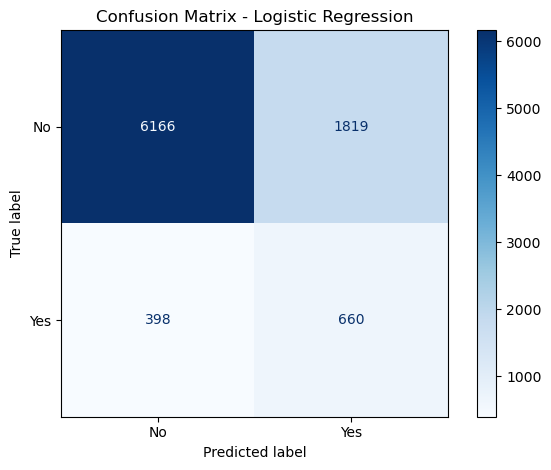


Confusion Matrix: Decision Tree


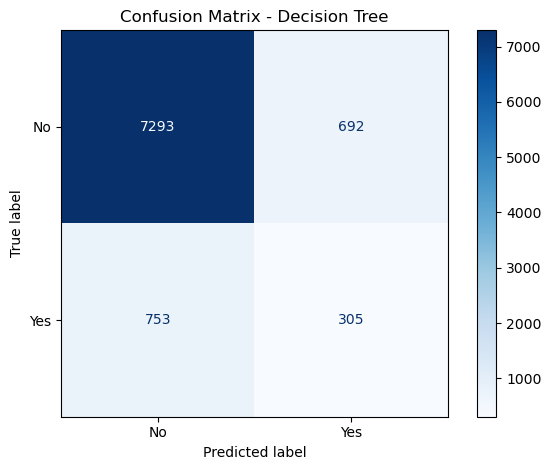


Confusion Matrix: KNN


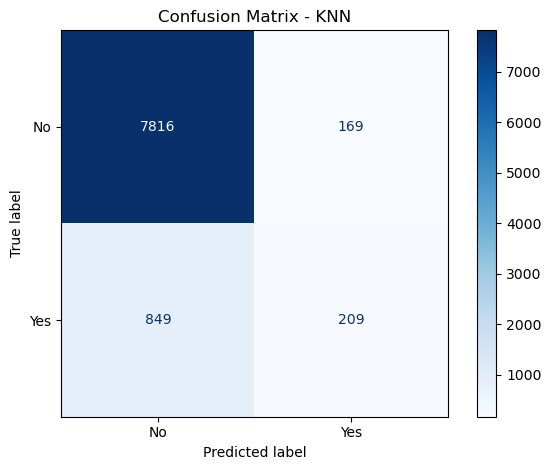


Confusion Matrix: Naive Bayes


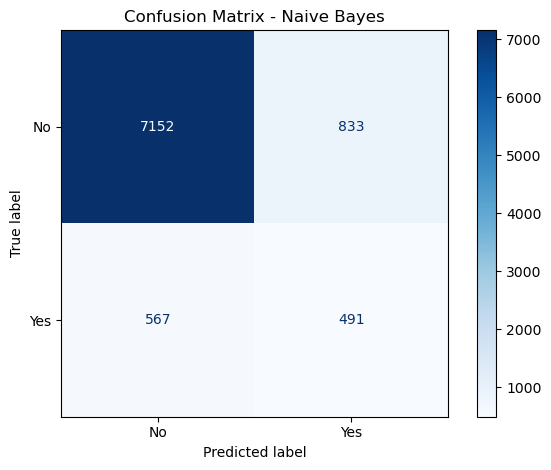


Confusion Matrix: SVM


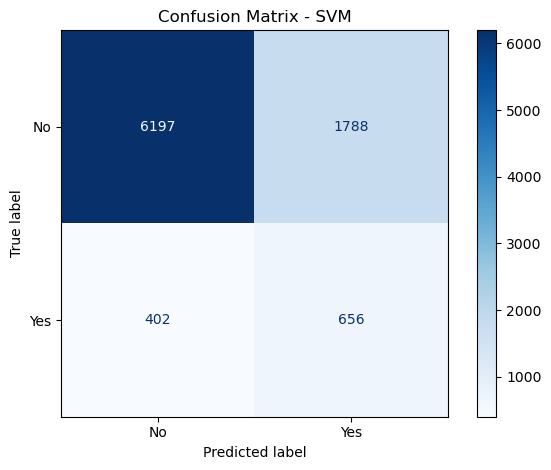

In [36]:
# Generate confusion matrices for all five models

for name, model in trained_models.items():

    print("\nConfusion Matrix:", name)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        model.predict(X_test),
        display_labels=["No", "Yes"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [38]:
# Create model directory if it does not exist
os.makedirs("model", exist_ok=True)

# Save all five trained models
model_files = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree": "decision_tree.pkl",
    "KNN": "knn.pkl",
    "Naive Bayes": "naive_bayes.pkl",
    "SVM": "svm.pkl"
}

for name, filename in model_files.items():

    model_path = os.path.join("model", filename)

    joblib.dump(trained_models[name], model_path)

    print(f"{name} saved successfully at {model_path}")

print("\nAll five models saved successfully!")

Logistic Regression saved successfully at model\logistic_regression.pkl
Decision Tree saved successfully at model\decision_tree.pkl
KNN saved successfully at model\knn.pkl
Naive Bayes saved successfully at model\naive_bayes.pkl
SVM saved successfully at model\svm.pkl

All five models saved successfully!


In [40]:
# Combine test features and target variable
test_data = X_test.copy()
test_data["y"] = y_test

# Save test dataset as CSV
test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)

print("\nFirst five records:")
display(test_data.head())

Test dataset saved successfully!
Test dataset shape: (9043, 16)

First five records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
1392,40,blue-collar,married,primary,no,640,yes,yes,unknown,8,may,2,-1,0,unknown,0
7518,44,technician,married,secondary,no,378,yes,no,unknown,30,may,2,-1,0,unknown,0
12007,31,services,married,secondary,no,356,yes,no,unknown,20,jun,5,-1,0,unknown,0
5536,36,blue-collar,married,primary,no,655,yes,no,unknown,23,may,4,-1,0,unknown,0
29816,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,1,-1,0,unknown,0


In [42]:
# Sort models by F1 Score
results_ranked = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

# Save comparison results
results_ranked.to_csv("model_comparison.csv", index=False)

# Display comparison table
print("Model Performance Comparison:")
display(results_ranked.round(4))

# Identify the best model based on F1 Score
best_model_name = results_ranked.iloc[0]["Model"]

print("\nBest Model based on F1 Score:", best_model_name)

print("\nModel comparison results saved successfully!")

Model Performance Comparison:


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Naive Bayes,0.8452,0.7514,0.3708,0.4641,0.4123,0.3271
1,SVM,0.7578,0.7718,0.2684,0.6200,0.3746,0.2867
2,Logistic Regression,0.7548,0.7722,0.2662,0.6238,0.3732,0.2853
3,Decision Tree,0.8402,0.6008,0.3059,0.2883,0.2968,0.2069
4,KNN,0.8874,0.7027,0.5529,0.1975,0.2911,0.2833



Best Model based on F1 Score: Naive Bayes

Model comparison results saved successfully!


In [46]:
# Verify saved model files

print("Verifying saved models...\n")

for name, filename in model_files.items():

    model_path = os.path.join("model", filename)

    # Load saved model
    loaded_model = joblib.load(model_path)

    # Test prediction using saved model
    predictions = loaded_model.predict(X_test)

    print(
        f"{name}: Loaded successfully | "
        f"Predictions generated: {len(predictions)}"
    )

# Verify test dataset
print("\nTest dataset exists:", os.path.exists("test_data.csv"))

print("\nVerification completed!")

Verifying saved models...

Logistic Regression: Loaded successfully | Predictions generated: 9043
Decision Tree: Loaded successfully | Predictions generated: 9043
KNN: Loaded successfully | Predictions generated: 9043
Naive Bayes: Loaded successfully | Predictions generated: 9043
SVM: Loaded successfully | Predictions generated: 9043

Test dataset exists: True

Verification completed!


In [48]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# ==========================================
# STREAMLIT PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="Bank Marketing Classification",
    page_icon="📊",
    layout="wide"
)

st.title("Bank Marketing Subscription Prediction")
st.write(
    "Performance evaluation of five machine learning "
    "classification models."
)

# ==========================================
# DEFINE FILE PATHS
# ==========================================

BASE_DIR = Path(__file__).resolve().parent
MODEL_DIR = BASE_DIR / "model"

MODEL_FILES = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree": "decision_tree.pkl",
    "KNN": "knn.pkl",
    "Naive Bayes": "naive_bayes.pkl",
    "SVM": "svm.pkl"
}

FEATURES = [
    "age", "job", "marital", "education", "default",
    "balance", "housing", "loan", "contact", "day",
    "month", "campaign", "pdays", "previous", "poutcome"
]

# ==========================================
# MODEL SELECTION
# ==========================================

st.sidebar.header("Model Selection")

selected_model = st.sidebar.selectbox(
    "Choose Classification Model",
    list(MODEL_FILES.keys())
)

# ==========================================
# LOAD TEST DATA
# ==========================================

st.header("Upload Test Dataset")

uploaded_file = st.file_uploader(
    "Upload a CSV file containing test features and target column",
    type=["csv"]
)

if uploaded_file is not None:
    try:
        test_data = pd.read_csv(uploaded_file)
        st.success("Uploaded test dataset successfully!")
    except Exception as error:
        st.error(f"Unable to read CSV file: {error}")
        st.stop()
else:
    default_file = BASE_DIR / "test_data.csv"

    if default_file.exists():
        test_data = pd.read_csv(default_file)
        st.info("Using the default test_data.csv file.")
    else:
        st.warning("Please upload a test dataset to continue.")
        st.stop()

# ==========================================
# VALIDATE TEST DATA
# ==========================================

if "y" not in test_data.columns:
    st.error("The uploaded CSV must contain the target column 'y'.")
    st.stop()

missing_features = [
    feature for feature in FEATURES
    if feature not in test_data.columns
]

if missing_features:
    st.error(f"Missing required features: {missing_features}")
    st.stop()

X_test = test_data[FEATURES].copy()

# Convert target into binary format
y_test = test_data["y"].copy()

if y_test.dtype == "object":
    y_test = y_test.astype(str).str.strip().str.lower()
    y_test = y_test.map({"no": 0, "yes": 1})

y_test = pd.to_numeric(y_test, errors="coerce")

if y_test.isnull().any() or not set(y_test.unique()).issubset({0, 1}):
    st.error("Target column 'y' must contain only 0/1 or no/yes values.")
    st.stop()

y_test = y_test.astype(int)

if len(y_test) == 0:
    st.error("The uploaded test dataset is empty.")
    st.stop()

if y_test.nunique() != 2:
    st.error("The test dataset must contain both target classes for AUC.")
    st.stop()

st.write("Test Dataset Shape:", test_data.shape)
st.dataframe(test_data.head())

# ==========================================
# LOAD SELECTED MODEL
# ==========================================

st.header("Model Evaluation")

model_path = MODEL_DIR / MODEL_FILES[selected_model]

if not model_path.exists():
    st.error(f"Model file not found: {model_path}")
    st.stop()

try:
    model = joblib.load(model_path)
except Exception as error:
    st.error(f"Unable to load model: {error}")
    st.stop()

# ==========================================
# GENERATE PREDICTIONS
# ==========================================

try:
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

except Exception as error:
    st.error(f"Prediction failed: {error}")
    st.stop()

# ==========================================
# CALCULATE EVALUATION METRICS
# ==========================================

accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_score)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
mcc = matthews_corrcoef(y_test, y_pred)

# ==========================================
# DISPLAY METRICS
# ==========================================

st.subheader(f"Performance Metrics: {selected_model}")

col1, col2, col3 = st.columns(3)

col1.metric("Accuracy", f"{accuracy:.4f}")
col2.metric("AUC", f"{auc:.4f}")
col3.metric("Precision", f"{precision:.4f}")

col4, col5, col6 = st.columns(3)

col4.metric("Recall", f"{recall:.4f}")
col5.metric("F1 Score", f"{f1:.4f}")
col6.metric("MCC", f"{mcc:.4f}")

# ==========================================
# CONFUSION MATRIX
# ==========================================

st.subheader("Confusion Matrix")

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
)

st.dataframe(cm_df)

# ==========================================
# CLASSIFICATION REPORT
# ==========================================

st.subheader("Classification Report")

report = classification_report(
    y_test,
    y_pred,
    target_names=["No", "Yes"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

st.dataframe(report_df.round(4))

st.success("Model evaluation completed successfully!")

Writing app.py


In [62]:
# Generate requirements.txt

requirements = [
    "streamlit==1.32.0",
    "pandas==2.2.2",
    "numpy==1.26.4",
    "scikit-learn==1.4.2",
    "matplotlib==3.8.4",
    "joblib==1.4.2"
]

with open("requirements.txt", "w") as file:
    file.write("\n".join(requirements) + "\n")

print("requirements.txt created successfully!")
print("\nRequired packages:")
for package in requirements:
    print(package)

requirements.txt created successfully!

Required packages:
streamlit==1.32.0
pandas==2.2.2
numpy==1.26.4
scikit-learn==1.4.2
matplotlib==3.8.4
joblib==1.4.2


In [58]:
%%writefile README.md

# Bank Marketing Subscription Prediction

## 1. Problem Statement

The objective of this project is to develop and compare five machine learning classification models to predict whether a bank customer will subscribe to a term deposit based on customer and campaign-related information.

The models used are:
1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

## 2. Dataset Description

Dataset Name: Bank Marketing Dataset

Source: UCI Machine Learning Repository

Dataset Link:
https://archive.ics.uci.edu/dataset/222/bank+marketing

Total Records: 45,211

Original Features: 16

Target Variable: y

Classification Type: Binary Classification

Target Classes:
- Yes: Customer subscribed to a term deposit.
- No: Customer did not subscribe to a term deposit.

The duration feature was excluded because it represents call duration and would not be available before making the call. Therefore, 15 input features were used for modelling.

## 3. Data Preprocessing

The following preprocessing techniques were applied:

- Checked for duplicate records and missing values.
- Retained unknown categorical values as a separate category.
- Converted the target variable into binary format (Yes = 1, No = 0).
- Applied median imputation and StandardScaler to numerical features.
- Applied most-frequent imputation and OneHotEncoder to categorical features.
- Used an 80:20 stratified train-test split.
- Used random_state = 42 for reproducibility.

Training Records: 36,168

Testing Records: 9,043

## 4. Model Evaluation

All five models were evaluated using the same test dataset.

The following six evaluation metrics were calculated:
- Accuracy
- AUC
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

### Model Comparison

| Model | Accuracy | AUC | Precision | Recall | F1 Score | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.7548 | 0.7722 | 0.2662 | 0.6238 | 0.3732 | 0.2853 |
| Decision Tree | 0.8402 | 0.6008 | 0.3059 | 0.2883 | 0.2968 | 0.2069 |
| KNN | 0.8874 | 0.7027 | 0.5529 | 0.1975 | 0.2911 | 0.2833 |
| Naive Bayes | 0.8452 | 0.7514 | 0.3708 | 0.4641 | 0.4123 | 0.3271 |
| SVM | 0.7578 | 0.7718 | 0.2684 | 0.6200 | 0.3746 | 0.2867 |

## 5. Model Observations

### Logistic Regression
Achieved the highest AUC of 0.7722, indicating good ability to distinguish between the two classes across different classification thresholds. It also achieved a recall of 0.6238.

### Decision Tree
Achieved an accuracy of 0.8402 but had a relatively low AUC of 0.6008 and F1 Score of 0.2968.

### KNN
Achieved the highest accuracy of 0.8874 and precision of 0.5529. However, its recall was only 0.1975, indicating that it missed many actual subscribers.

### Naive Bayes
Achieved the highest F1 Score of 0.4123 and MCC of 0.3271. It provided the best balance between precision and recall among the five models.

### Support Vector Machine
Achieved an AUC of 0.7718 and recall of 0.6200. It performed similarly to Logistic Regression in identifying actual subscribers, although its precision was relatively low.

## 6. Overall Conclusion

Naive Bayes was the best-performing model based on F1 Score and MCC.

Although KNN achieved the highest accuracy, it had the lowest recall. This demonstrates why accuracy alone is not sufficient for evaluating models on an imbalanced dataset.

Naive Bayes provided the best overall balance between precision and recall for this classification task.

## 7. GitHub Repository

https://github.com/Anuskabits/aiml-ml-classification-assignment-2

## 8. Streamlit Application

Live application link: To be added after deployment.

The Streamlit application allows users to:
- Select one of the five trained classification models.
- Upload a test CSV dataset.
- View all six evaluation metrics.
- View the confusion matrix.
- View the classification report.

The application loads the saved trained models and does not perform retraining.

## 9. Project Structure

- app.py: Streamlit application.
- ML_Assignment_2.ipynb: Model implementation and evaluation.
- requirements.txt: Required Python libraries and versions.
- test_data.csv: Test dataset.
- model_comparison.csv: Model comparison results.
- model/: Saved trained classification pipelines.

Writing README.md
